In [1]:
import gc
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy import sparse
from tqdm import tqdm


def iter_chunks(index, chunk_size):
    for start in range(0, len(index), chunk_size):
        yield index[start:start + chunk_size]


def total_chunks(length, chunk_size):
    return (length + chunk_size - 1) // chunk_size


def read_chunk_csr(adata, obs_names, var_indices=None):
    view = adata[obs_names, var_indices] if var_indices is not None else adata[obs_names]
    x = view.X
    if sparse.issparse(x):
        x = x.tocsr()
    else:
        x = sparse.csr_matrix(np.asarray(x))
    return x.astype(np.float32)


def make_unique(labels, fallback_index):
    labels = pd.Series(labels, index=pd.Index(fallback_index), dtype='object')
    labels = labels.fillna(labels.index.to_series()).astype(str)
    duplicated = labels.duplicated(keep=False)
    labels.loc[duplicated] = labels.loc[duplicated] + '|' + labels.index[duplicated].astype(str)
    return labels.to_numpy()


In [2]:
adata = sc.read_h5ad("/nas/project1/PAGE_PJH/01.rawdata/01.perturb-seq/hek293t.h5ad", backed = "r")

In [3]:
gene_meta_path = '/nas/project1/PAGE_PJH/01.rawdata/01.perturb-seq/xatlas_orion/metadata/gene_metadata.parquet'
gene_meta = pd.read_parquet(gene_meta_path).set_index('ensembl_id').reindex(adata.var_names)

adata.var = adata.var.copy()
adata.var['ensembl_id'] = adata.var_names
adata.var['gene_name'] = gene_meta['gene_name'].fillna(pd.Series(adata.var_names, index=adata.var_names)).to_numpy()
adata.var['gene_token_id'] = gene_meta['gene_token_id'].to_numpy()
adata.var['gene_name_unique'] = make_unique(adata.var['gene_name'], adata.var_names)

adata.obs['gene'] = adata.obs['gene_target']
adata.obs['batch'] = adata.obs['sample']


In [4]:
# 2) guide count table
gene_counts = (
    adata.obs[['gene']]
    .dropna(subset=['gene'])
    .groupby('gene', as_index=False)
    .size()
    .rename(columns={'size': 'n_cells'})
    .sort_values('n_cells', ascending=False)
)

# 3) blacklist guide labels with too few cells
min_cells_per_gene = 10
blacklist = gene_counts.loc[gene_counts['n_cells'] < min_cells_per_gene, 'gene'].tolist()

print(f"#blacklist genes (<{min_cells_per_gene} cells): {len(blacklist)}")
print("examples:", blacklist[:10])

adata.obs['is_blacklisted_gene'] = adata.obs['gene'].isin(blacklist)
control_label = 'Non-Targeting'
filt_mask = (~adata.obs['is_blacklisted_gene']).to_numpy()
filt_obs_names = adata.obs_names[filt_mask]

expr_chunk_size = 2000
gene_sum = np.zeros(adata.n_vars, dtype=np.float64)
for chunk_cells in tqdm(
    iter_chunks(filt_obs_names, expr_chunk_size),
    total=total_chunks(len(filt_obs_names), expr_chunk_size),
    desc='mean_umi'
):
    x = read_chunk_csr(adata, chunk_cells)
    gene_sum += np.asarray(x.sum(axis=0)).ravel().astype(np.float64, copy=False)
    del x
    gc.collect()

mean_umi_per_gene = gene_sum / max(len(filt_obs_names), 1)
min_mean_umi = 0.01
gene_mask = mean_umi_per_gene > min_mean_umi
selected_gene_idx = np.flatnonzero(gene_mask)
selected_var = adata.var.iloc[selected_gene_idx].copy()
selected_var = selected_var.set_index('gene_name_unique', drop=False)
selected_feature_names = selected_var.index.to_numpy()

adata.var['mean_umi_per_filtered_cell'] = mean_umi_per_gene
adata.var['keep_min_umi'] = gene_mask

print(f"filtered cells after guide blacklist: {int(filt_mask.sum())}/{adata.n_obs}")
print(f"genes with mean UMI > {min_mean_umi} per filtered cell: {int(gene_mask.sum())}/{adata.n_vars}")


#blacklist genes (<10 cells): 137
examples: ['CCT2', 'CEP192', 'TMEM185A', 'SPC24', 'ZNF549', 'CALB2', 'DHX8', 'PCF11', 'NDST3', 'ATM']



mean_umi:   0%|                                                                                                                                                                                    | 0/2267 [00:00<?, ?it/s]


mean_umi:   0%|                                                                                                                                                                          | 1/2267 [00:11<7:12:46, 11.46s/it]


mean_umi:   0%|▏                                                                                                                                                                         | 2/2267 [00:12<3:27:24,  5.49s/it]


mean_umi:   0%|▏                                                                                                                                                                         | 3/2267 [00:14<2:15:02,  3.58s/it]


mean_umi:   0%|▎                                                                                                                                                                         | 4/2267 [00:15<1:41:06,  2.68s/it]

... (2,261 outputs left out)


mean_umi: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▉| 2266/2267 [52:35<00:02,  2.38s/it]


mean_umi: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2267/2267 [52:37<00:00,  2.24s/it]


mean_umi: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2267/2267 [52:37<00:00,  1.39s/it]

filtered cells after guide blacklist: 4533532/4534299
genes with mean UMI > 0.01 per filtered cell: 18295/38606


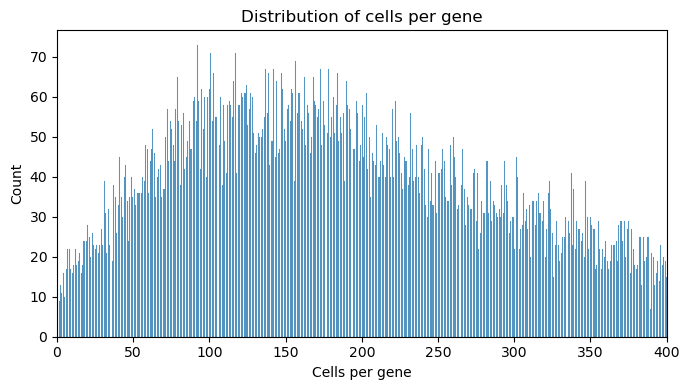

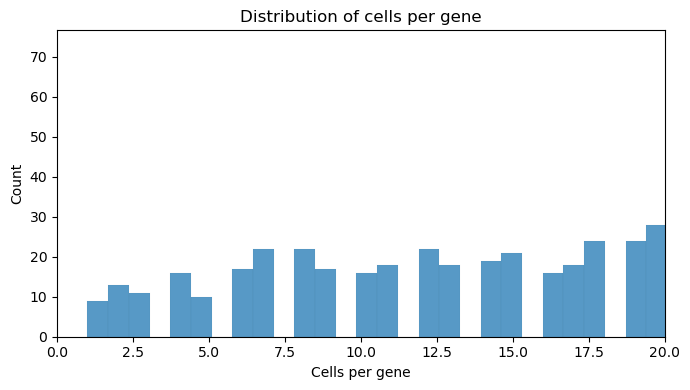

In [5]:
import seaborn as sns
plt.figure(figsize=(7,4))
sns.histplot(gene_counts[~gene_counts['gene'].isin(["Non-Targeting"])]['n_cells'], bins=2000)
plt.xlim(0, 400)    
plt.xlabel('Cells per gene')
plt.title('Distribution of cells per gene')
plt.tight_layout()
plt.show()


plt.figure(figsize=(7,4))
sns.histplot(gene_counts[~gene_counts['gene'].isin(["Non-Targeting"])]['n_cells'], bins=2000)
plt.xlim(0, 20)    
plt.xlabel('Cells per gene')
plt.title('Distribution of cells per gene')
plt.tight_layout()
plt.show()


In [6]:
# backed AnnData는 view of view가 안 되므로 항상 원본 adata에서 직접 슬라이싱
pert_mask = filt_mask & adata.obs['gene'].ne(control_label).to_numpy()
control_mask = filt_mask & adata.obs['gene'].eq(control_label).to_numpy()
matrix_obs = adata.obs.loc[pert_mask].copy()
control_matrix_obs = adata.obs.loc[control_mask].copy()


In [7]:
matrix_obs

,sample,num_features,guide_target,gene_target,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,pass_guide_filter,gene,batch,is_blacklisted_gene
AAACCAAAGAAGTAGC-HEK293T_Batch1,HEK293T_Batch1,2,FAM180A_P1P2-1|FAM180A_P1P2-2,FAM180A,6856,24243.0,647.0,2.668812,1,FAM180A,HEK293T_Batch1,False
AAACCAAAGAGTGGGC-HEK293T_Batch1,HEK293T_Batch1,2,PCDHGC4_P1P2-1|PCDHGC4_P1P2-2,PCDHGC4,5353,14035.0,610.0,4.346277,1,PCDHGC4,HEK293T_Batch1,False
AAACCAAAGAGTGTAA-HEK293T_Batch1,HEK293T_Batch1,2,USP30_P1P2-1|USP30_P1P2-2,USP30,6358,20939.0,589.0,2.812933,1,USP30,HEK293T_Batch1,False
AAACCAAAGATACGGG-HEK293T_Batch1,HEK293T_Batch1,2,KLRD1_P1P2-1|KLRD1_P1P2-2,KLRD1,5527,14083.0,476.0,3.379961,1,KLRD1,HEK293T_Batch1,False
AAACCAAAGCAGGCTT-HEK293T_Batch1,HEK293T_Batch1,2,FAM118A_P1P2-1|FAM118A_P1P2-2,FAM118A,6138,21989.0,629.0,2.860521,1,FAM118A,HEK293T_Batch1,False
...,...,...,...,...,...,...,...,...,...,...,...,...
GTTGTCCGTATGGTTA-HEK293T_Batch223,HEK293T_Batch223,2,CYB5R4_P1P2-1|CYB5R4_P1P2-2,CYB5R4,10896,88861.0,2961.0,3.332170,1,CYB5R4,HEK293T_Batch223,False
GTTGTCTTCAACAGCC-HEK293T_Batch223,HEK293T_Batch223,2,AKAP13_P1P2-1|AKAP13_P1P2-2,AKAP13,10568,88551.0,3035.0,3.427403,1,AKAP13,HEK293T_Batch223,False
GTTGTCTTCAGTACTG-HEK293T_Batch223,HEK293T_Batch223,2,TTF2_P1P2-1|TTF2_P1P2-2,TTF2,10735,81286.0,1808.0,2.224245,1,TTF2,HEK293T_Batch223,False
GTTGTCTTCCGCCGTT-HEK293T_Batch223,HEK293T_Batch223,2,MMP7_P1P2-1|MMP7_P1P2-2,MMP7,9248,40733.0,1767.0,4.338006,1,MMP7,HEK293T_Batch223,False


In [8]:
chunk_size = 2000
n_features = len(selected_gene_idx)
control_output_path = Path('/tmp/xaira_hek293_ntc_zscore.float32.dat')
if control_output_path.exists():
    control_output_path.unlink()

pert_positions = np.flatnonzero(pert_mask)
control_positions = np.flatnonzero(control_mask)
pert_batches = matrix_obs['batch'].to_numpy()
control_batches = control_matrix_obs['batch'].to_numpy()
pert_guides = matrix_obs['gene'].to_numpy()

assert len(pert_positions) == len(matrix_obs)
assert len(control_positions) == len(control_matrix_obs)

def read_selected_chunk(obs_indexer):
    x = read_chunk_csr(adata, obs_indexer)
    return x[:, selected_gene_idx].tocsr()

batch_reads_per_bc = np.empty(len(pert_positions), dtype=np.float32)
batch_order = pd.Index(pd.unique(pert_batches))
pert_batch_codes, _ = pd.factorize(pert_batches, sort=False)

total_pert_chunks = total_chunks(len(pert_positions), chunk_size)
for chunk_idx, start in enumerate(tqdm(range(0, len(pert_positions), chunk_size), total=total_pert_chunks, desc='batch_median')):
    end = min(start + chunk_size, len(pert_positions))
    x = read_selected_chunk(pert_positions[start:end])
    batch_reads_per_bc[start:end] = np.asarray(x.sum(axis=1)).ravel().astype(np.float32, copy=False)
    del x
    if (chunk_idx + 1) % 25 == 0:
        gc.collect()

median_reads_cache = {}
for batch_code, gem in enumerate(batch_order):
    batch_mask = pert_batch_codes == batch_code
    reads_per_bc = batch_reads_per_bc[batch_mask]
    median_reads_cache[gem] = float(np.median(reads_per_bc)) if len(reads_per_bc) else 0.0
    print('gemgroup', gem, ':', (int(batch_mask.sum()), n_features), 'median_reads', median_reads_cache[gem])

del batch_reads_per_bc
control_target_medians = np.asarray([median_reads_cache[gem] for gem in control_batches], dtype=np.float32)
pert_target_medians = np.asarray([median_reads_cache[gem] for gem in pert_batches], dtype=np.float32)
gc.collect()

control_sum = np.zeros(n_features, dtype=np.float64)
control_sumsq = np.zeros(n_features, dtype=np.float64)
control_n = 0
total_control_chunks = total_chunks(len(control_positions), chunk_size)
for chunk_idx, start in enumerate(tqdm(range(0, len(control_positions), chunk_size), total=total_control_chunks, desc='control_stats')):
    end = min(start + chunk_size, len(control_positions))
    x = read_selected_chunk(control_positions[start:end])
    control_reads_per_bc = np.asarray(x.sum(axis=1)).ravel().astype(np.float32, copy=False)
    control_scaling_factors = np.divide(
        control_target_medians[start:end],
        control_reads_per_bc,
        out=np.ones_like(control_reads_per_bc, dtype=np.float32),
        where=control_reads_per_bc != 0,
    )
    x = x.multiply(control_scaling_factors[:, None]).tocsr()
    control_sum += np.asarray(x.sum(axis=0)).ravel().astype(np.float64, copy=False)
    control_sumsq += np.asarray(x.power(2).sum(axis=0)).ravel().astype(np.float64, copy=False)
    control_n += x.shape[0]
    del x, control_reads_per_bc, control_scaling_factors
    if (chunk_idx + 1) % 25 == 0:
        gc.collect()

control_mean = (control_sum / max(control_n, 1)).astype(np.float32)
control_var = (control_sumsq - control_n * np.square(control_mean.astype(np.float64))) / max(control_n - 1, 1)
control_std = np.sqrt(np.clip(control_var, a_min=0, a_max=None)).astype(np.float32)
control_std[control_std == 0] = 1

print('Building control AnnData matrix on disk...')
control_matrix = np.memmap(
    control_output_path,
    dtype='float32',
    mode='w+',
    shape=(control_matrix_obs.shape[0], n_features),
)
control_row = 0
for chunk_idx, start in enumerate(tqdm(range(0, len(control_positions), chunk_size), total=total_control_chunks, desc='control_zscore')):
    end = min(start + chunk_size, len(control_positions))
    x = read_selected_chunk(control_positions[start:end])
    control_reads_per_bc = np.asarray(x.sum(axis=1)).ravel().astype(np.float32, copy=False)
    control_scaling_factors = np.divide(
        control_target_medians[start:end],
        control_reads_per_bc,
        out=np.ones_like(control_reads_per_bc, dtype=np.float32),
        where=control_reads_per_bc != 0,
    )
    x = x.multiply(control_scaling_factors[:, None]).tocsr()
    dense_chunk = x.toarray().astype(np.float32, copy=False)
    dense_chunk -= control_mean[None, :]
    dense_chunk /= control_std[None, :]
    next_row = control_row + dense_chunk.shape[0]
    control_matrix[control_row:next_row] = dense_chunk
    control_row = next_row
    del x, control_reads_per_bc, control_scaling_factors, dense_chunk
    if (chunk_idx + 1) % 25 == 0:
        gc.collect()
control_matrix.flush()

print('Accumulating perturbation guide means...')
guide_codes, guide_order = pd.factorize(pert_guides, sort=True)
guide_sum = np.zeros((len(guide_order), n_features), dtype=np.float64)
guide_count = np.bincount(guide_codes, minlength=len(guide_order)).astype(np.int64)
for chunk_idx, start in enumerate(tqdm(range(0, len(pert_positions), chunk_size), total=total_pert_chunks, desc='perturb_zscore')):
    end = min(start + chunk_size, len(pert_positions))
    x = read_selected_chunk(pert_positions[start:end])
    reads_per_bc = np.asarray(x.sum(axis=1)).ravel().astype(np.float32, copy=False)
    scaling_factors = np.divide(
        pert_target_medians[start:end],
        reads_per_bc,
        out=np.ones_like(reads_per_bc, dtype=np.float32),
        where=reads_per_bc != 0,
    )
    x = x.multiply(scaling_factors[:, None]).tocsr()

    chunk_codes = guide_codes[start:end]
    unique_codes, inverse = np.unique(chunk_codes, return_inverse=True)
    group_matrix = sparse.csr_matrix(
        (np.ones(len(chunk_codes), dtype=np.float32), (inverse, np.arange(len(chunk_codes)))),
        shape=(len(unique_codes), len(chunk_codes)),
    )
    guide_sum[unique_codes] += (group_matrix @ x).toarray().astype(np.float64, copy=False)

    del x, reads_per_bc, scaling_factors, chunk_codes, unique_codes, inverse, group_matrix
    if (chunk_idx + 1) % 25 == 0:
        gc.collect()

adata_ntc_memmap_path = control_output_path
adata_ntc = sc.AnnData(control_matrix, obs=control_matrix_obs.copy(), var=selected_var.copy())

ko_means_noncentered_values = guide_sum / guide_count[:, None]
ko_means_noncentered_values -= control_mean[None, :].astype(np.float64, copy=False)
ko_means_noncentered_values /= control_std[None, :].astype(np.float64, copy=False)
ko_means_noncentered = pd.DataFrame(
    ko_means_noncentered_values.astype(np.float32),
    index=guide_order,
    columns=selected_feature_names,
)

print('Done.')



batch_median:   0%|                                                                                                                                                                                | 0/2158 [00:00<?, ?it/s]


batch_median:   0%|                                                                                                                                                                      | 1/2158 [00:02<1:15:25,  2.10s/it]


batch_median:   0%|▏                                                                                                                                                                     | 2/2158 [00:03<1:06:43,  1.86s/it]


batch_median:   0%|▏                                                                                                                                                                     | 3/2158 [00:05<1:02:44,  1.75s/it]


batch_median:   0%|▎                                                                                                                                                                     | 4/2158 [00:06<1:00:33,  1.69s/it]


batch_median:   0%|▍                                                                                                                                                                     | 5/2158 [00:08<1:00:43,  1.69s/it]

... (4,547 outputs left out)


perturb_zscore: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▉| 2157/2158 [56:05<00:01,  1.93s/it]


perturb_zscore: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2158/2158 [56:05<00:00,  1.53s/it]


perturb_zscore: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2158/2158 [56:05<00:00,  1.56s/it]

Done.


In [9]:
print('adata_ntc shape:', adata_ntc.shape)
print('ko_means_noncentered shape:', ko_means_noncentered.shape)


adata_ntc shape: (218838, 18295)
ko_means_noncentered shape: (18174, 18295)


In [10]:
ko_means_noncentered.to_csv('/nas/project1/PAGE_PJH/02.processed/xaira_orion_hek293_gwps_min10cells_noncentered_effectsize.csv.gz')
ko_means = ko_means_noncentered - ko_means_noncentered.mean(axis=0)


In [11]:
for name in [
    'adata', 'gene_sum', 'mean_umi_per_gene', 'filt_obs_names', 'filt_mask', 'pert_mask',
    'control_mask', 'matrix_obs', 'control_matrix_obs', 'selected_gene_idx', 'control_sum',
    'control_sumsq', 'control_n', 'control_var', 'median_reads_cache', 'guide_sum', 'guide_count',
    'ko_means_noncentered',
]:
    globals().pop(name, None)

gc.collect()


1686